<a href="https://colab.research.google.com/github/magnogomes874/SSD-/blob/main/MVP%20-%20FreeFlow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MVP — Previsão de tráfego e estimativa de economia de tempo em pedágios *free flow*: uma análise da BR-101/RJ



**Magno Gomes Sousa — 200031031**


**Base de dados:** https://dados.antt.gov.br/dataset/volume-trafego-praca-pedagio



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import hashlib, io, zipfile, json
from IPython.display import display
SAIDA = Path('resultados_freeflow')
SAIDA.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False, 'axes.spines.right': False})


## 1. Carga dos registros utilizados

**Free flow:** Itaguaí, Mangaratiba e Paraty, RIOSP.

**Autopista Fluminense**: Casimiro de Abreu, Conselheiro Josino, Rio Bonito e Serrinha. São Gonçalo não integra a comparação principal porque sua cobrança é unidirecional.

A classificação vem do cadastro e da documentação dos pontos, não do rótulo Manual.

Todos ficam na BR-101/RJ, em trechos diferentes.

A unidade é passagem registrada; um mesmo veículo pode aparecer várias vezes.



In [2]:
# Execute esta célula e selecione somente registros_comparacao.csv.
from google.colab import files

def carregar_csv(arquivos):
    if len(arquivos) != 1:
        raise ValueError('Selecione exatamente um arquivo: registros_comparacao.csv.')
    nome, conteudo = next(iter(arquivos.items()))
    if not nome.lower().endswith('.csv'):
        raise ValueError('Selecione o CSV extraído do ZIP, não o próprio ZIP.')
    tabela = pd.read_csv(io.BytesIO(conteudo), sep=';', encoding='utf-8-sig', dtype=str, keep_default_na=False)
    obrigatorias = {'id_registro','arquivo_origem','concessionaria','praca','competencia','sentido',
        'tipo_de_veiculo','tipo_cobranca','campo_categoria_origem','categoria_informada',
        'volume_total','revisao_necessaria','ano','mes','sistema'}
    faltantes = obrigatorias - set(tabela.columns)
    if faltantes:
        raise ValueError('Colunas ausentes: '+', '.join(sorted(faltantes))+
                         '. Utilize registros_comparacao.csv do pacote da comparação.')
    numerico = pd.to_numeric(tabela.volume_total, errors='raise')
    if numerico.isna().any() or not numerico.ge(0).all() or not numerico.mod(1).eq(0).all():
        raise ValueError('Volume vazio, negativo ou fracionário. Revise a base antes de continuar.')
    tabela['volume'] = numerico.astype('int64')
    tabela['ano'] = pd.to_numeric(tabela.ano, errors='raise').astype(int)
    tabela['mes'] = pd.to_numeric(tabela.mes, errors='raise').astype(int)
    datas = pd.to_datetime(tabela.competencia, format='%Y-%m', errors='raise')
    if not datas.dt.year.eq(tabela.ano).all() or not datas.dt.month.eq(tabela.mes).all():
        raise ValueError('Ano/mês não correspondem à competência.')
    porticos = {'FREE FLOW ITAGUAÍ','FREE FLOW MANGARATIBA','FREE FLOW PARATY'}
    pracas = {'CASIMIRO DE ABREU','CONSELHEIRO JOSINO','RIO BONITO','SERRINHA'}
    ff = tabela.concessionaria.eq('RIOSP') & tabela.praca.isin(porticos) & tabela.sistema.eq('FREE_FLOW')
    convencional = tabela.concessionaria.eq('AUTOPISTA FLUMINENSE') & tabela.praca.isin(pracas) & tabela.sistema.eq('CONVENCIONAL')
    if not (ff | convencional).all():
        raise ValueError('Há pontos ou classificações fora do recorte definido.')
    metadados = {'arquivo_importado': nome, 'sha256': hashlib.sha256(conteudo).hexdigest(),
                 'registros': len(tabela), 'importado_em_utc': pd.Timestamp.now(tz='UTC').isoformat()}
    return tabela, metadados

arquivos = files.upload()
base, metadados_importacao = carregar_csv(arquivos)
(SAIDA/'metadados_importacao.json').write_text(json.dumps(metadados_importacao, ensure_ascii=False, indent=2), encoding='utf-8')
print('Arquivo importado:', metadados_importacao['arquivo_importado'])
print('Registros:', len(base))
display(base[['id_registro','concessionaria','praca','competencia','sentido','volume','sistema']].head())


Saving registros_comparacao (1).csv to registros_comparacao (1).csv
Arquivo importado: registros_comparacao (1).csv
Registros: 3450


,id_registro,concessionaria,praca,competencia,sentido,volume,sistema
0,2024-000008862,AUTOPISTA FLUMINENSE,CASIMIRO DE ABREU,2024-01,CRESCENTE,129743,CONVENCIONAL
1,2024-000008864,AUTOPISTA FLUMINENSE,CASIMIRO DE ABREU,2024-01,CRESCENTE,716,CONVENCIONAL
2,2024-000008866,AUTOPISTA FLUMINENSE,CASIMIRO DE ABREU,2024-01,CRESCENTE,251,CONVENCIONAL
3,2024-000008875,AUTOPISTA FLUMINENSE,CASIMIRO DE ABREU,2024-01,CRESCENTE,126268,CONVENCIONAL
4,2024-000008877,AUTOPISTA FLUMINENSE,CASIMIRO DE ABREU,2024-01,CRESCENTE,780,CONVENCIONAL


## 2. Validações do recorte

As verificações impedem que alterações na entrada produzam uma comparação silenciosamente incompleta, onde a ausência de alerta estrutural não certifica a veracidade da informação reportada. Categorias e modalidades de cobrança ausentes não são preenchidas com zeros.

In [3]:
assert base.id_registro.is_unique, 'IDs repetidos'
assert base.tipo_de_veiculo.eq('PASSEIO').all()
assert base.revisao_necessaria.eq('0').all(), 'Há pendências da limpeza no recorte'
assert base.volume.ge(0).all() and base.volume.mod(1).eq(0).all()
base['volume'] = base.volume.astype('int64')
assert set(base.sistema) == {'FREE_FLOW','CONVENCIONAL'}
assert base.groupby('sistema').praca.nunique().to_dict() == {'CONVENCIONAL':4,'FREE_FLOW':3}
chave = ['concessionaria','competencia','sentido','praca','tipo_cobranca','campo_categoria_origem','categoria_informada','tipo_de_veiculo']
assert not base.duplicated(chave).any()
mensal = base.groupby(['competencia','sistema','praca'], as_index=False).agg(volume=('volume','sum'), sentidos=('sentido','nunique'))
meses_esperados = set(pd.period_range('2024-01','2026-08',freq='M').astype(str))
assert len(mensal)==224 and set(mensal.competencia)==meses_esperados
assert mensal.sentidos.eq(2).all()
assert mensal.groupby('praca').competencia.nunique().eq(32).all()
assert mensal.volume.sum()==base.volume.sum()
mensal['dias_corridos'] = pd.to_datetime(mensal.competencia+'-01').dt.days_in_month
mensal['media_diaria'] = mensal.volume/mensal.dias_corridos
print('Validações aprovadas: 7 pontos, 32 meses, 224 combinações mês/ponto, dois sentidos.')


Validações aprovadas: 7 pontos, 32 meses, 224 combinações mês/ponto, dois sentidos.


## 3. Comparação de períodos equivalentes

Média diária por ponto = soma de passagens ÷ (número de pontos × dias corridos).

O denominador usa o calendário; os arquivos não comprovam dias efetivos de operação. Os totais de três pórticos e quatro praças são normalizados pelo número de pontos.

Janeiro–agosto é exibido nos três anos; anos completos somente em 2024 e 2025.

In [4]:
linhas=[]
for ano in [2024,2025,2026]:
    for mes_final in ([8,12] if ano<2026 else [8]):
        sub=mensal[mensal.competencia.str[:4].eq(str(ano)) & mensal.competencia.str[-2:].astype(int).le(mes_final)]
        for sistema,g in sub.groupby('sistema'):
            dias=int(g[['competencia','dias_corridos']].drop_duplicates().dias_corridos.sum())
            pontos=g.praca.nunique()
            volume=int(g.volume.sum())
            linhas.append(dict(ano=ano,mes_final=mes_final,sistema=sistema,pontos=pontos,dias_corridos=dias,passagens_passeio=volume,media_passagens_dia_por_ponto=volume/(pontos*dias)))
comparacao=pd.DataFrame(linhas)
display(comparacao.round(2))
por_ponto=mensal[mensal.competencia.str.startswith('2025')].groupby(['sistema','praca'],as_index=False).volume.sum()
por_ponto['media_diaria_2025']=por_ponto.volume/365
display(por_ponto.sort_values('media_diaria_2025',ascending=False).round(2))


,ano,mes_final,sistema,pontos,dias_corridos,passagens_passeio,media_passagens_dia_por_ponto
0,2024,8,CONVENCIONAL,4,244,9707584,9946.30
1,2024,8,FREE_FLOW,3,244,8448237,11541.31
2,2024,12,CONVENCIONAL,4,366,14708509,10046.80
3,2024,12,FREE_FLOW,3,366,12784442,11643.39
4,2025,8,CONVENCIONAL,4,243,9527756,9802.22
5,2025,8,FREE_FLOW,3,243,8718781,11959.92
6,2025,12,CONVENCIONAL,4,365,14225292,9743.35
7,2025,12,FREE_FLOW,3,365,13130088,11990.95
8,2026,8,CONVENCIONAL,4,243,10511523,10814.32
9,2026,8,FREE_FLOW,3,243,9216844,12643.13


,sistema,praca,volume,media_diaria_2025
4,FREE_FLOW,FREE FLOW ITAGUAÍ,8578863,23503.73
0,CONVENCIONAL,CASIMIRO DE ABREU,5031031,13783.65
2,CONVENCIONAL,RIO BONITO,4816420,13195.67
5,FREE_FLOW,FREE FLOW MANGARATIBA,3069947,8410.81
3,CONVENCIONAL,SERRINHA,3032568,8308.41
6,FREE_FLOW,FREE FLOW PARATY,1481278,4058.30
1,CONVENCIONAL,CONSELHEIRO JOSINO,1345273,3685.68


## 4. Gráficos

As diferenças entre os pontos refletem também localização, demanda, tarifas e características do trecho.

Lembrando que o desenho é descritivo e não identifica o efeito causal do sistema de cobrança.

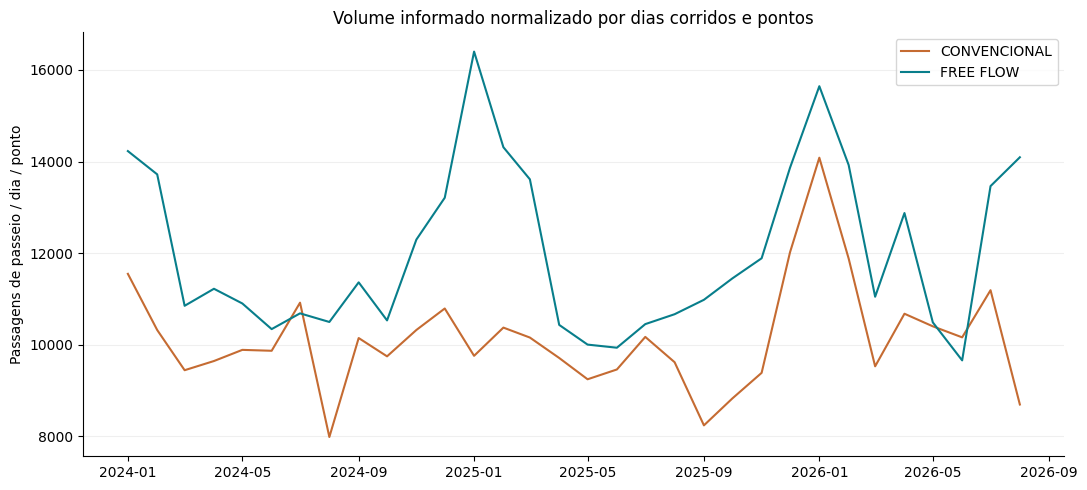

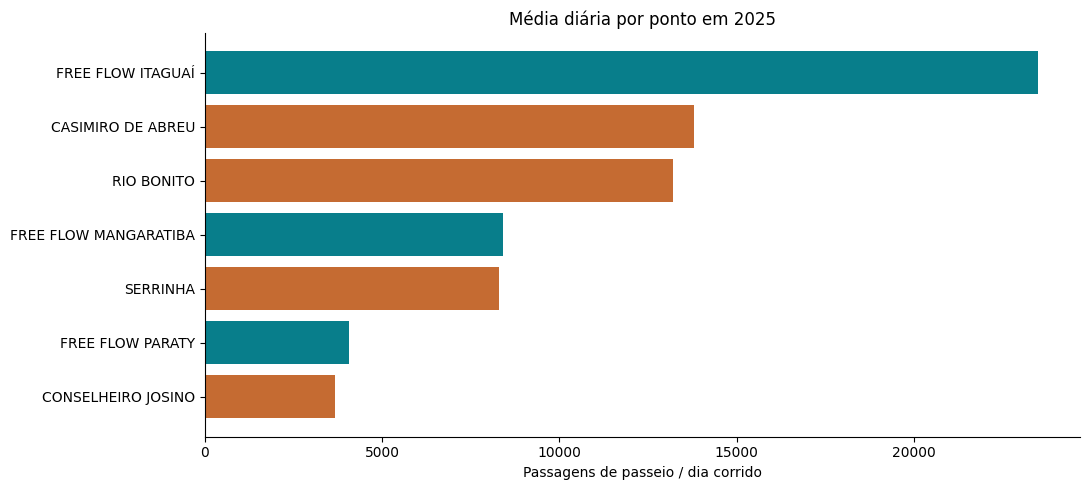

In [5]:
cores={'FREE_FLOW':'#087E8B','CONVENCIONAL':'#C56B32'}
grupos=mensal.groupby(['competencia','sistema'],as_index=False).agg(volume=('volume','sum'),pontos=('praca','nunique'),dias=('dias_corridos','first'))
grupos['media_diaria_por_ponto']=grupos.volume/(grupos.pontos*grupos.dias)
fig,ax=plt.subplots()
for sistema,g in grupos.groupby('sistema'):
    ax.plot(pd.to_datetime(g.competencia),g.media_diaria_por_ponto,label=sistema.replace('_',' '),color=cores[sistema])
ax.set(ylabel='Passagens de passeio / dia / ponto',title='Volume informado normalizado por dias corridos e pontos')
ax.legend();ax.grid(axis='y',alpha=.2);fig.tight_layout();fig.savefig(SAIDA/'evolucao_mensal.png',dpi=180);plt.show()
p=por_ponto.sort_values('media_diaria_2025')
fig,ax=plt.subplots()
ax.barh(p.praca,p.media_diaria_2025,color=p.sistema.map(cores))
ax.set(xlabel='Passagens de passeio / dia corrido',title='Média diária por ponto em 2025')
fig.tight_layout();fig.savefig(SAIDA/'comparacao_pontos_2025.png',dpi=180);plt.show()


## 5. Previsão de tráfego: protocolo temporal

**Unidade prevista:** passagens mensais de passeio por ponto.

**Validação:** treinar até dezembro/2024 e prever janeiro–dezembro/2025.

**Teste final:** treinar até dezembro/2025 e prever janeiro–agosto/2026, os meses futuros são previstos de uma só vez em cada corte; nenhum volume futuro entra no treinamento.

Compararemos persistência, média dos últimos três meses, sazonal do ano anterior, Ridge e Random Forest. A escolha usa somente o MAE da validação de 2025.

O teste de 2026 serve para avaliação, sem selecionar novamente o modelo.

Parâmetros fixados previamente: Ridge alpha=10; Random Forest com 200 árvores, folha mínima 3, semente 42;Há apenas 32 meses por ponto.

Os resultados descrevem este pequeno conjunto e não estabelecem o efeito do free flow.

MAE/RMSE em passagens por mês/ponto; WMAPE = soma dos erros absolutos / soma dos volumes reais. R² pode ser negativo. MAE por ponto acompanha a métrica global para tornar visível a heterogeneidade.


In [6]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

painel = mensal[['competencia','sistema','praca','volume']].copy()
painel['data'] = pd.to_datetime(painel.competencia+'-01')
painel = painel.sort_values(['data','praca']).reset_index(drop=True)
PONTOS = sorted(painel.praca.unique())
MODELOS = ['Persistencia','Media_3_meses','Sazonal_12_meses','Ridge','Random_Forest']

def atributos(tabela):
    dt = pd.to_datetime(tabela.competencia+'-01')
    f = pd.DataFrame(index=tabela.index)
    f['tendencia'] = ((dt.dt.year-2024)*12+dt.dt.month-1)/12
    f['mes_seno'] = np.sin(2*np.pi*dt.dt.month/12)
    f['mes_cosseno'] = np.cos(2*np.pi*dt.dt.month/12)
    for ponto in PONTOS:
        f['ponto_'+ponto] = tabela.praca.eq(ponto).astype(int)
    return f

def prever(treino, futuro, nome):
    treino = treino.sort_values(['data','praca'])
    assert treino.data.max() < futuro.data.min()
    if nome == 'Persistencia':
        valores = treino.groupby('praca').tail(1).set_index('praca').volume
        pred = futuro.praca.map(valores).to_numpy(dtype=float)
    elif nome == 'Media_3_meses':
        valores = treino.groupby('praca').tail(3).groupby('praca').volume.mean()
        pred = futuro.praca.map(valores).to_numpy(dtype=float)
    elif nome == 'Sazonal_12_meses':
        anterior = (pd.to_datetime(futuro.competencia+'-01')-pd.DateOffset(years=1)).dt.strftime('%Y-%m')
        lookup = treino.set_index(['competencia','praca']).volume
        pred = np.array([lookup.get((mes,ponto),np.nan) for mes,ponto in zip(anterior,futuro.praca)],dtype=float)
    else:
        modelo = (Ridge(alpha=10) if nome=='Ridge' else
                  RandomForestRegressor(n_estimators=200,min_samples_leaf=3,random_state=42,n_jobs=-1))
        modelo.fit(atributos(treino),treino.volume)
        pred = modelo.predict(atributos(futuro))
    if not np.isfinite(pred).all():
        raise ValueError('Previsão indisponível; confira a cobertura necessária para '+nome)
    return np.maximum(pred,0)  # previsão negativa é limitada a zero, sem alterar observações

def avaliar(treino, futuro, etapa):
    previsoes=[]; metricas=[]
    for nome in MODELOS:
        pred = prever(treino,futuro,nome)
        real = futuro.volume.to_numpy()
        linha={'etapa':etapa,'modelo':nome,'observacoes':len(real),
               'MAE':mean_absolute_error(real,pred),'RMSE':np.sqrt(mean_squared_error(real,pred)),
               'R2':r2_score(real,pred),'WMAPE':np.abs(real-pred).sum()/real.sum()}
        metricas.append(linha)
        detalhe=futuro[['competencia','sistema','praca','volume']].copy()
        detalhe['modelo']=nome; detalhe['etapa']=etapa; detalhe['previsto']=pred
        detalhe['erro_absoluto']=np.abs(detalhe.volume-detalhe.previsto)
        previsoes.append(detalhe)
    return pd.DataFrame(metricas),pd.concat(previsoes,ignore_index=True)

treino_val=painel[painel.data.lt('2025-01-01')]
validacao=painel[painel.data.between('2025-01-01','2025-12-01')]
metricas_val,prev_val=avaliar(treino_val,validacao,'validacao_2025')
modelo_escolhido=metricas_val.sort_values(['MAE','modelo']).iloc[0].modelo
print('Escolha pelo MAE de 2025:',modelo_escolhido)
display(metricas_val.sort_values('MAE').round(4))

treino_teste=painel[painel.data.lt('2026-01-01')]
teste=painel[painel.data.ge('2026-01-01')]
assert len(treino_val)==84 and len(validacao)==84 and len(treino_teste)==168 and len(teste)==56
metricas_teste,prev_teste=avaliar(treino_teste,teste,'teste_2026_jan_ago')
metricas_teste['selecionado_na_validacao']=metricas_teste.modelo.eq(modelo_escolhido)
display(metricas_teste.sort_values('MAE').round(4))
metricas=pd.concat([metricas_val,metricas_teste],ignore_index=True)
previsoes_avaliacao=pd.concat([prev_val,prev_teste],ignore_index=True)
mae_por_ponto=prev_teste.groupby(['modelo','sistema','praca'],as_index=False).erro_absoluto.mean().rename(columns={'erro_absoluto':'MAE'})
display(mae_por_ponto[mae_por_ponto.modelo.eq(modelo_escolhido)].round(2))


Escolha pelo MAE de 2025: Sazonal_12_meses


,etapa,modelo,observacoes,MAE,RMSE,R2,WMAPE
2,validacao_2025,Sazonal_12_meses,84,28390.2738,40831.5272,0.9587,0.0872
4,validacao_2025,Random_Forest,84,29792.6970,45940.1542,0.9477,0.0915
1,validacao_2025,Media_3_meses,84,39172.1508,55940.7442,0.9224,0.1203
0,validacao_2025,Persistencia,84,53958.8571,71520.9469,0.8732,0.1657
3,validacao_2025,Ridge,84,73885.1505,101091.5633,0.7467,0.2269


,etapa,modelo,observacoes,MAE,RMSE,R2,WMAPE,selecionado_na_validacao
1,teste_2026_jan_ago,Media_3_meses,56,41595.7440,61694.8562,0.9153,0.1181,False
4,teste_2026_jan_ago,Random_Forest,56,43642.7378,65145.0916,0.9056,0.1239,False
2,teste_2026_jan_ago,Sazonal_12_meses,56,46671.2143,69357.4264,0.8930,0.1325,True
0,teste_2026_jan_ago,Persistencia,56,60661.5893,79509.6115,0.8594,0.1722,False
3,teste_2026_jan_ago,Ridge,56,65185.1189,93081.1011,0.8073,0.1850,False


,modelo,sistema,praca,MAE
28,Sazonal_12_meses,CONVENCIONAL,CASIMIRO DE ABREU,65209.25
29,Sazonal_12_meses,CONVENCIONAL,CONSELHEIRO JOSINO,14134.50
30,Sazonal_12_meses,CONVENCIONAL,RIO BONITO,53301.00
31,Sazonal_12_meses,CONVENCIONAL,SERRINHA,38467.88
32,Sazonal_12_meses,FREE_FLOW,FREE FLOW ITAGUAÍ,102800.00
33,Sazonal_12_meses,FREE_FLOW,FREE FLOW MANGARATIBA,37174.75
34,Sazonal_12_meses,FREE_FLOW,FREE FLOW PARATY,15611.12


### Previsão de setembro a dezembro/2026

Após concluir a avaliação, o modelo escolhido na validação é ajustado com todos os meses observados até agosto/202, esta é uma projeção futura, sem valores reais para conferir no arquivo atual.

O sistema de cobrança de cada ponto é o rótulo histórico do recorte; mudanças posteriores a agosto/2026 precisam de revisão antes do uso operacional da projeção.


,competencia,praca,sistema,volume_previsto,modelo,natureza
0,2026-09,CASIMIRO DE ABREU,CONVENCIONAL,353305.0,Sazonal_12_meses,PROJECAO_SEM_REAL_OBSERVADO
1,2026-09,CONSELHEIRO JOSINO,CONVENCIONAL,80694.0,Sazonal_12_meses,PROJECAO_SEM_REAL_OBSERVADO
2,2026-09,FREE FLOW ITAGUAÍ,FREE_FLOW,654241.0,Sazonal_12_meses,PROJECAO_SEM_REAL_OBSERVADO
3,2026-09,FREE FLOW MANGARATIBA,FREE_FLOW,227765.0,Sazonal_12_meses,PROJECAO_SEM_REAL_OBSERVADO
4,2026-09,FREE FLOW PARATY,FREE_FLOW,105998.0,Sazonal_12_meses,PROJECAO_SEM_REAL_OBSERVADO
5,2026-09,RIO BONITO,CONVENCIONAL,341514.0,Sazonal_12_meses,PROJECAO_SEM_REAL_OBSERVADO
6,2026-09,SERRINHA,CONVENCIONAL,212524.0,Sazonal_12_meses,PROJECAO_SEM_REAL_OBSERVADO
7,2026-10,CASIMIRO DE ABREU,CONVENCIONAL,386487.0,Sazonal_12_meses,PROJECAO_SEM_REAL_OBSERVADO
8,2026-10,CONSELHEIRO JOSINO,CONVENCIONAL,91259.0,Sazonal_12_meses,PROJECAO_SEM_REAL_OBSERVADO
9,2026-10,FREE FLOW ITAGUAÍ,FREE_FLOW,702041.0,Sazonal_12_meses,PROJECAO_SEM_REAL_OBSERVADO


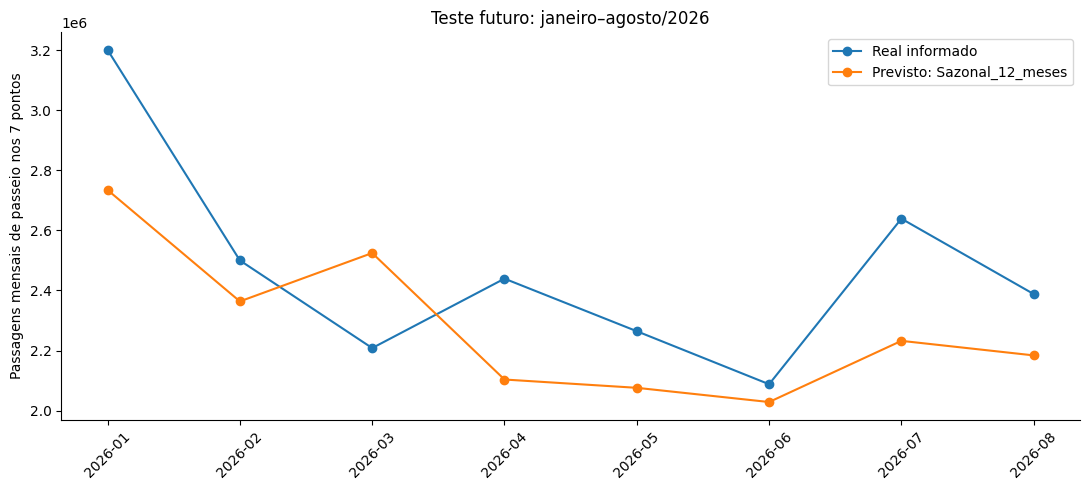

In [7]:
futuros=[]
for mes in pd.period_range('2026-09','2026-12',freq='M').astype(str):
    for ponto in PONTOS:
        sistema=painel.loc[painel.praca.eq(ponto),'sistema'].iloc[0]
        futuros.append({'competencia':mes,'praca':ponto,'sistema':sistema})
projecao=pd.DataFrame(futuros)
projecao['data']=pd.to_datetime(projecao.competencia+'-01')
projecao['volume_previsto']=prever(painel,projecao,modelo_escolhido)
projecao['modelo']=modelo_escolhido
projecao['natureza']='PROJECAO_SEM_REAL_OBSERVADO'
assert len(projecao)==28 and np.isfinite(projecao.volume_previsto).all()
display(projecao.drop(columns='data').round(2))

fig,ax=plt.subplots()
real_teste=teste.groupby('competencia').volume.sum()
pred_teste=prev_teste[prev_teste.modelo.eq(modelo_escolhido)].groupby('competencia').previsto.sum()
ax.plot(real_teste.index,real_teste.values,label='Real informado',marker='o')
ax.plot(pred_teste.index,pred_teste.values,label='Previsto: '+modelo_escolhido,marker='o')
ax.set(ylabel='Passagens mensais de passeio nos 7 pontos',title='Teste futuro: janeiro–agosto/2026')
ax.legend();ax.tick_params(axis='x',rotation=45);fig.tight_layout()
fig.savefig(SAIDA/'previsao_teste_2026.png',dpi=180);plt.show()


## 6. Economia potencial de tempo — referência externa configurada

43 s correspondem à redução **simulada de travessia da área da praça em Itaúna/MG**, e não a uma fila medida na Rio–Santos.

Os cálculos principais pressupõem que o parâmetro seja a média sobre todas as passagens, a sensibilidade de 21,5 e 64,5s não é intervalo de confiança ou previsão.

A ocupação fica ausente, pois não se estimam horas-pessoa.


In [8]:
ATRASO_EVITADO_SEG = 43.0  # cenário transferido da literatura, não medição local
FONTE_ATRASO = 'Estudo de caso Itaúna/MG, Revista dos Transportes Públicos ANTP (2024), redução simulada de 43 segundos na travessia da praça, sentido leste. Transferência de parâmetro para cenário de veículos de passeio na Rio-Santos; sem calibração local. https://files.antp.org.br/2024/7/30/rtp-156-e_1.pdf'
OCUPACAO_MEDIA = None     # opcional; pessoas por veículo de passeio
FONTE_OCUPACAO = ''

def estimar_tempo(volumes,atraso_seg,fonte,ocupacao=None,fonte_ocupacao=''):
    if atraso_seg is None:
        return None
    if not isinstance(atraso_seg,(int,float)) or not np.isfinite(atraso_seg) or atraso_seg<0 or not fonte.strip():
        raise ValueError('Informe atraso finito >= 0 e sua fonte.')
    if ocupacao is not None and (not isinstance(ocupacao,(int,float)) or not np.isfinite(ocupacao) or ocupacao<1 or not fonte_ocupacao.strip()):
        raise ValueError('Informe ocupação finita >= 1 e sua fonte, ou deixe None.')
    out=volumes.copy()
    out['atraso_evitado_seg']=atraso_seg
    out['horas_veiculo_estimadas']=out['passagens_base']*atraso_seg/3600
    out['fonte_atraso']=fonte
    out['ocupacao_media']=ocupacao
    out['horas_pessoa_estimadas']=np.nan if ocupacao is None else out.horas_veiculo_estimadas*ocupacao
    out['fonte_ocupacao']=fonte_ocupacao
    return out

volumes_tempo=mensal[mensal.sistema.eq('FREE_FLOW')][['competencia','praca','volume']].rename(columns={'volume':'passagens_base'}).copy()
volumes_tempo['natureza_passagens']='HISTORICO_INFORMADO'
volumes_futuros=projecao[projecao.sistema.eq('FREE_FLOW')][['competencia','praca','volume_previsto']].rename(columns={'volume_previsto':'passagens_base'}).copy()
volumes_futuros['natureza_passagens']='PROJECAO'
base_tempo=pd.concat([volumes_tempo,volumes_futuros],ignore_index=True)
economia_tempo=estimar_tempo(base_tempo,ATRASO_EVITADO_SEG,FONTE_ATRASO,OCUPACAO_MEDIA,FONTE_OCUPACAO)
if economia_tempo is None:
    print('Pendente: preencher atraso evitado e fonte. Nenhuma economia de tempo foi calculada.')
else:
    display(economia_tempo.round(3))

# Sensibilidade definida pelo analista: 50%, 100% e 150% do parâmetro externo.
# Estes fatores NÃO são intervalo de confiança nem limites medidos.
cenarios=[]
for fator in [0.5,1.0,1.5]:
    out=estimar_tempo(base_tempo,43*fator,FONTE_ATRASO)
    out['fator_sensibilidade']=fator
    cenarios.append(out)
sensibilidade_tempo=pd.concat(cenarios,ignore_index=True)
resumo_tempo=sensibilidade_tempo.assign(ano=sensibilidade_tempo.competencia.str[:4]).groupby(
    ['ano','natureza_passagens','fator_sensibilidade','atraso_evitado_seg'],as_index=False).agg(
    passagens=('passagens_base','sum'),horas_veiculo=('horas_veiculo_estimadas','sum'))
print('Cenários: histórico informado e projeções futuras apresentados separadamente.')
display(resumo_tempo.round(2))


,competencia,praca,passagens_base,natureza_passagens,atraso_evitado_seg,horas_veiculo_estimadas,fonte_atraso,ocupacao_media,horas_pessoa_estimadas,fonte_ocupacao
0,2024-01,FREE FLOW ITAGUAÍ,837368.0,HISTORICO_INFORMADO,43.0,10001.896,"Estudo de caso Itaúna/MG, Revista dos Transpor...",None,NaN,
1,2024-01,FREE FLOW MANGARATIBA,313017.0,HISTORICO_INFORMADO,43.0,3738.814,"Estudo de caso Itaúna/MG, Revista dos Transpor...",None,NaN,
2,2024-01,FREE FLOW PARATY,172809.0,HISTORICO_INFORMADO,43.0,2064.108,"Estudo de caso Itaúna/MG, Revista dos Transpor...",None,NaN,
3,2024-02,FREE FLOW ITAGUAÍ,781967.0,HISTORICO_INFORMADO,43.0,9340.161,"Estudo de caso Itaúna/MG, Revista dos Transpor...",None,NaN,
4,2024-02,FREE FLOW MANGARATIBA,277880.0,HISTORICO_INFORMADO,43.0,3319.122,"Estudo de caso Itaúna/MG, Revista dos Transpor...",None,NaN,
...,...,...,...,...,...,...,...,...,...,...
103,2026-11,FREE FLOW MANGARATIBA,251214.0,PROJECAO,43.0,3000.612,"Estudo de caso Itaúna/MG, Revista dos Transpor...",None,NaN,
104,2026-11,FREE FLOW PARATY,120268.0,PROJECAO,43.0,1436.534,"Estudo de caso Itaúna/MG, Revista dos Transpor...",None,NaN,
105,2026-12,FREE FLOW ITAGUAÍ,848310.0,PROJECAO,43.0,10132.592,"Estudo de caso Itaúna/MG, Revista dos Transpor...",None,NaN,
106,2026-12,FREE FLOW MANGARATIBA,297175.0,PROJECAO,43.0,3549.590,"Estudo de caso Itaúna/MG, Revista dos Transpor...",None,NaN,


Cenários: histórico informado e projeções futuras apresentados separadamente.


,ano,natureza_passagens,fator_sensibilidade,atraso_evitado_seg,passagens,horas_veiculo
0,2024,HISTORICO_INFORMADO,0.5,21.5,12784442.0,76351.53
1,2024,HISTORICO_INFORMADO,1.0,43.0,12784442.0,152703.06
2,2024,HISTORICO_INFORMADO,1.5,64.5,12784442.0,229054.59
3,2025,HISTORICO_INFORMADO,0.5,21.5,13130088.0,78415.80
4,2025,HISTORICO_INFORMADO,1.0,43.0,13130088.0,156831.61
5,2025,HISTORICO_INFORMADO,1.5,64.5,13130088.0,235247.41
6,2026,HISTORICO_INFORMADO,0.5,21.5,9216844.0,55045.04
7,2026,HISTORICO_INFORMADO,1.0,43.0,9216844.0,110090.08
8,2026,HISTORICO_INFORMADO,1.5,64.5,9216844.0,165135.12
9,2026,PROJECAO,0.5,21.5,4411307.0,26345.31


### Gráficos de síntese da economia potencial

O primeiro painel apresenta a estimativa por viagem e compara janeiro–agosto em todos os anos, o segundo mostra a contribuição de cada pórtico em 2025 e a dependência do resultado em relação ao atraso escolhido.

As horas agregadas refletem também o volume de passagens, uma barra maior não significa maior economia por motorista.

**Os gráficos não estimam redução percentual do tempo total do percurso.**


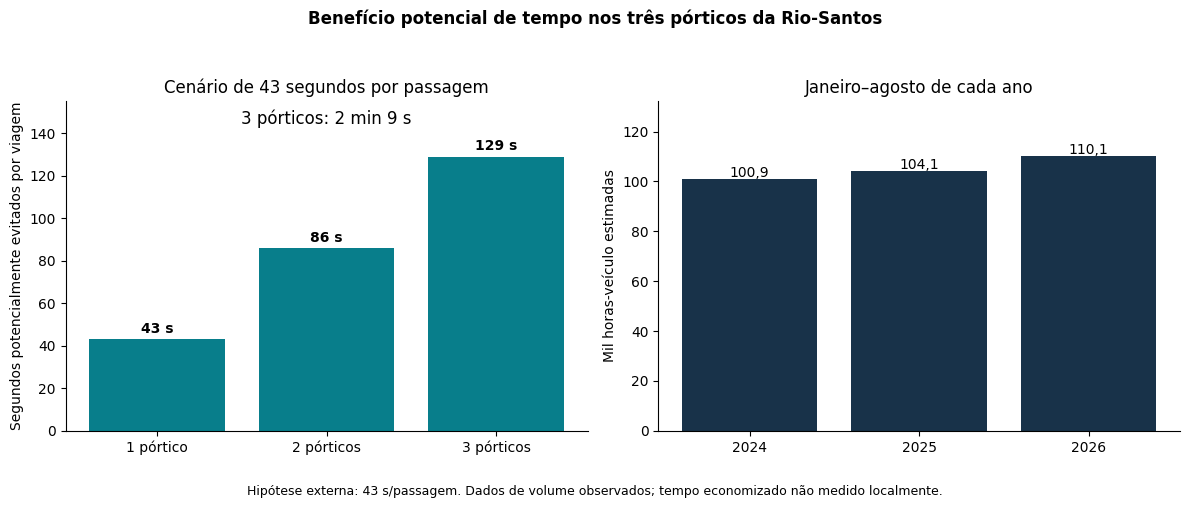

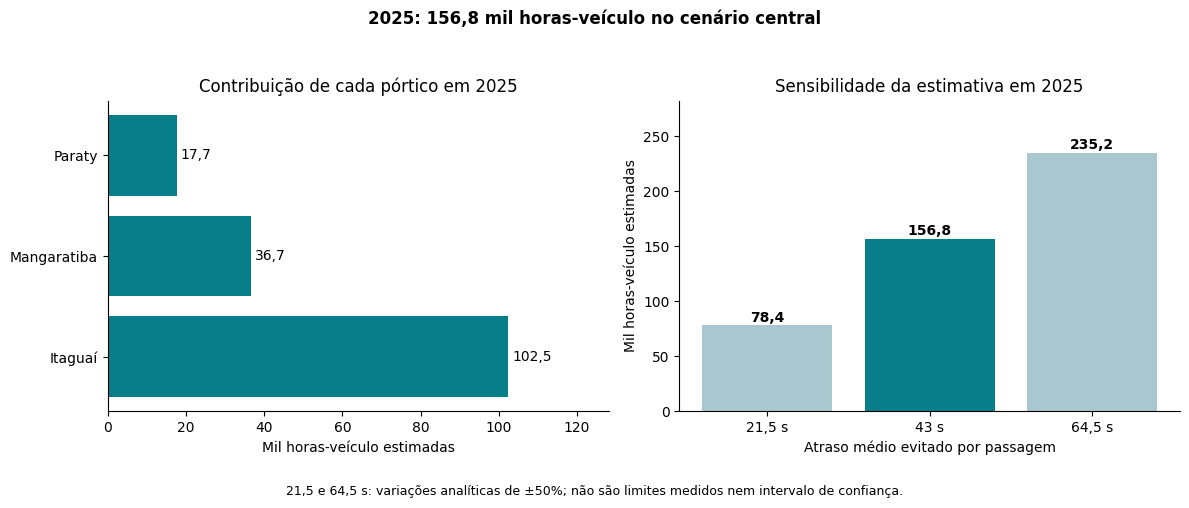

In [10]:
# Gráficos de síntese: estimativas condicionais, sem medição local.
from matplotlib.ticker import FuncFormatter
fmt = FuncFormatter(lambda x,pos:f'{x:,.0f}'.replace(',','.'))
fig,axs=plt.subplots(1,2,figsize=(12,5))
quantidades=np.array([1,2,3]);segundos=43*quantidades
axs[0].bar(['1 pórtico','2 pórticos','3 pórticos'],segundos,color='#087E8B')
for i,v in enumerate(segundos):
    axs[0].text(i,v+3,f'{v:.0f} s',ha='center',fontweight='bold')
axs[0].set(ylabel='Segundos potencialmente evitados por viagem',ylim=(0,155),title='Cenário de 43 segundos por passagem')
axs[0].text(.5,.93,'3 pórticos: 2 min 9 s',transform=axs[0].transAxes,ha='center',fontsize=12)
# Mesma janela em todos os anos, para permitir comparação.
meses8=mensal[mensal.sistema.eq('FREE_FLOW') & mensal.competencia.str[-2:].astype(int).le(8)].copy()
meses8['ano']=meses8.competencia.str[:4]
anuais=meses8.groupby('ano').volume.sum()*43/3600
axs[1].bar(anuais.index,anuais.values/1000,color='#183249')
for i,v in enumerate(anuais):axs[1].text(i,v/1000+1,f'{v/1000:.1f}'.replace('.',','),ha='center')
axs[1].set(ylabel='Mil horas-veículo estimadas',title='Janeiro–agosto de cada ano',ylim=(0,max(anuais)/1000*1.2))
fig.suptitle('Benefício potencial de tempo nos três pórticos da Rio-Santos',fontweight='bold')
fig.text(.5,.01,'Hipótese externa: 43 s/passagem. Dados de volume observados; tempo economizado não medido localmente.',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.06,1,.94]);fig.savefig(SAIDA/'sintese_tempo_viagem_anos.png',dpi=200);plt.show()

volume2025=mensal[mensal.sistema.eq('FREE_FLOW') & mensal.competencia.str.startswith('2025')].groupby('praca').volume.sum()
fig,axs=plt.subplots(1,2,figsize=(12,5))
horas=volume2025*43/3600
nomes=[v.replace('FREE FLOW ','').title() for v in horas.index]
axs[0].barh(nomes,horas.values/1000,color='#087E8B')
for i,v in enumerate(horas):axs[0].text(v/1000+1,i,f'{v/1000:.1f}'.replace('.',','),va='center')
axs[0].set(xlabel='Mil horas-veículo estimadas',title='Contribuição de cada pórtico em 2025',xlim=(0,max(horas)/1000*1.25))
cen=43*np.array([.5,1,1.5]);total=volume2025.sum()*cen/3600
axs[1].bar(['21,5 s','43 s','64,5 s'],total/1000,color=['#A9C7CE','#087E8B','#A9C7CE'])
for i,v in enumerate(total):axs[1].text(i,v/1000+3,f'{v/1000:.1f}'.replace('.',','),ha='center',fontweight='bold')
axs[1].set(ylabel='Mil horas-veículo estimadas',xlabel='Atraso médio evitado por passagem',title='Sensibilidade da estimativa em 2025',ylim=(0,max(total)/1000*1.2))
fig.suptitle('2025: 156,8 mil horas-veículo no cenário central',fontweight='bold')
fig.text(.5,.01,'21,5 e 64,5 s: variações analíticas de ±50%; não são limites medidos nem intervalo de confiança.',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.06,1,.94]);fig.savefig(SAIDA/'tempo_2025_porticos_sensibilidade.png',dpi=200);plt.show()

# Guardar números que sustentam os gráficos.
resumo_grafico_tempo=pd.DataFrame({'porticos_na_viagem':quantidades,'segundos_estimados':segundos})
resumo_grafico_tempo.to_csv(SAIDA/'tempo_estimado_por_viagem.csv',sep=';',index=False,encoding='utf-8-sig')


### Cenários adicionais de retenção na praça convencional

Mantém-se a referência externa de **43 segundos de redução simulada de travessia**, que não é tempo de espera medido na Rio-Santos.
Acrescentam-se hipóteses de **atraso líquido evitado** de 60, 90 e 120 segundos por ponto, abrangendo aproximação, eventual fila e pagamento. Esses valores representam o tempo adicional frente à travessia em fluxo livre; não devem ser somados aos 43 segundos nem incluir novamente deslocamentos comuns aos dois sistemas.

O cenário de 120 segundos é pessimista quanto à retenção na praça convencional e, por isso, gera maior benefício potencial do free flow. Não é um limite máximo observado nem uma previsão de fila. O cenário de 90 segundos é apenas um valor intermediário analítico, sem distribuição probabilística. O cálculo de uma viagem com vários pontos pressupõe o mesmo atraso em cada ponto atravessado, não demonstra filas simultâneas.


,cenario,pontos_na_viagem,economia_seg,economia_min
0,Referência externa,1,43,0.716667
1,Referência externa,2,86,1.433333
2,Referência externa,3,129,2.150000
3,Retenção moderada,1,60,1.000000
4,Retenção moderada,2,120,2.000000
5,Retenção moderada,3,180,3.000000
6,Retenção elevada,1,90,1.500000
7,Retenção elevada,2,180,3.000000
8,Retenção elevada,3,270,4.500000
9,Maior retenção,1,120,2.000000


,cenario,ano,natureza_passagens,atraso_evitado_seg,passagens,horas_veiculo
0,Referência externa,2025,HISTORICO_INFORMADO,43,13130088.0,156831.61
1,Retenção moderada,2025,HISTORICO_INFORMADO,60,13130088.0,218834.80
2,Retenção elevada,2025,HISTORICO_INFORMADO,90,13130088.0,328252.20
3,Maior retenção,2025,HISTORICO_INFORMADO,120,13130088.0,437669.60


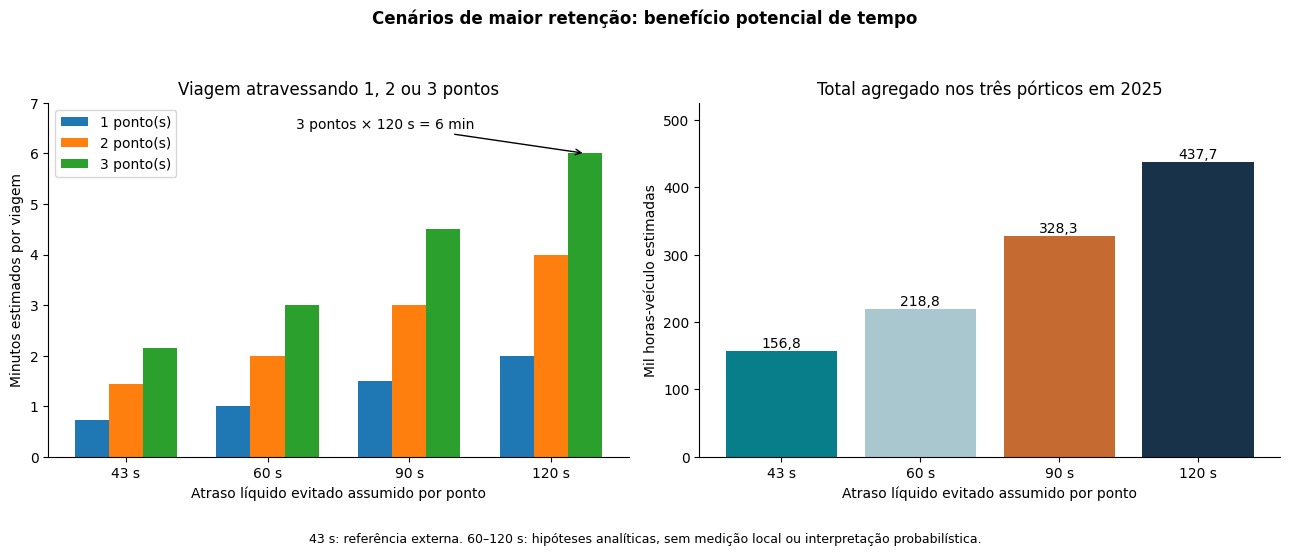

In [11]:
catalogo_retencao=pd.DataFrame([
    {'cenario':'Referência externa','atraso_seg':43,'origem':'Santos, Portugal e Ribeiro (2024); transferência sem calibração local'},
    {'cenario':'Retenção moderada','atraso_seg':60,'origem':'Hipótese analítica do trabalho'},
    {'cenario':'Retenção elevada','atraso_seg':90,'origem':'Hipótese analítica intermediária do trabalho'},
    {'cenario':'Maior retenção','atraso_seg':120,'origem':'Hipótese analítica do trabalho'}
])
linhas=[];detalhes=[]
for registro in catalogo_retencao.to_dict('records'):
    detalhe=estimar_tempo(base_tempo,registro['atraso_seg'],registro['origem'])
    detalhe['cenario']=registro['cenario'];detalhes.append(detalhe)
    for pontos in [1,2,3]:
        segundos=registro['atraso_seg']*pontos
        linhas.append({'cenario':registro['cenario'],'atraso_seg_por_ponto':registro['atraso_seg'],
                       'pontos_na_viagem':pontos,'economia_seg':segundos,
                       'economia_min':segundos/60,'origem':registro['origem']})
retencao_por_viagem=pd.DataFrame(linhas)
retencao_detalhada=pd.concat(detalhes,ignore_index=True)
retencao_resumo=retencao_detalhada.assign(ano=retencao_detalhada.competencia.str[:4]).groupby(
    ['ano','natureza_passagens','cenario','atraso_evitado_seg'],as_index=False).agg(
    passagens=('passagens_base','sum'),horas_veiculo=('horas_veiculo_estimadas','sum'))
retencao_2025=retencao_resumo[retencao_resumo.ano.eq('2025') & retencao_resumo.natureza_passagens.eq('HISTORICO_INFORMADO')].set_index('cenario').loc[catalogo_retencao.cenario].reset_index()
display(retencao_por_viagem[['cenario','pontos_na_viagem','economia_seg','economia_min']])
display(retencao_2025.round(2))
fig,axs=plt.subplots(1,2,figsize=(13,5.5))
x=np.arange(4);largura=.24
for j,pontos in enumerate([1,2,3]):
    valores=catalogo_retencao.atraso_seg.to_numpy()*pontos/60
    axs[0].bar(x+(j-1)*largura,valores,width=largura,label=f'{pontos} ponto(s)')
axs[0].set_xticks(x,['43 s','60 s','90 s','120 s'])
axs[0].set(xlabel='Atraso líquido evitado assumido por ponto',ylabel='Minutos estimados por viagem',title='Viagem atravessando 1, 2 ou 3 pontos',ylim=(0,7))
axs[0].legend()
axs[0].annotate('3 pontos × 120 s = 6 min',xy=(3+largura,6),xytext=(1.2,6.5),arrowprops={'arrowstyle':'->'})
valores=retencao_2025.horas_veiculo.to_numpy()/1000
axs[1].bar(x,valores,color=['#087E8B','#A9C7CE','#C56B32','#183249'])
axs[1].set_xticks(x,['43 s','60 s','90 s','120 s'])
for i,v in enumerate(valores):axs[1].text(i,v+5,f'{v:.1f}'.replace('.',','),ha='center')
axs[1].set(xlabel='Atraso líquido evitado assumido por ponto',ylabel='Mil horas-veículo estimadas',title='Total agregado nos três pórticos em 2025',ylim=(0,max(valores)*1.2))
fig.suptitle('Cenários de maior retenção: benefício potencial de tempo',fontweight='bold')
fig.text(.5,.01,'43 s: referência externa. 60–120 s: hipóteses analíticas, sem medição local ou interpretação probabilística.',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.06,1,.94]);fig.savefig(SAIDA/'cenarios_retencao_viagem_total_2025.png',dpi=200);plt.show()
assert retencao_por_viagem[(retencao_por_viagem.atraso_seg_por_ponto.eq(120)) & retencao_por_viagem.pontos_na_viagem.eq(3)].economia_seg.iloc[0]==360
assert np.isclose(retencao_2025.loc[retencao_2025.atraso_evitado_seg.eq(120),'horas_veiculo'].iloc[0],13130088*120/3600)


# 7. *Conclusão*


O MVP permitiu comparar a demanda informada e avaliar cinco modelos de previsão mensal, são eles:
-  Modelo sazonal foi escolhido na validação de 2025 e apresentou WMAPE de 13,25% no teste de janeiro a agosto de 2026.

- A média de três meses apresentou o menor erro nesse teste (11,81%), sem alterar retrospectivamente a escolha feita na validação.


Nos três pórticos, as 13.130.088 passagens de passeio de 2025 corresponderam a 156,8 mil a 437,7 mil horas-veículo potenciais, conforme os atrasos assumidos de 43 a 120 segundos, de setembro a dezembro de 2026, a projeção pontual de 4.411.307 passagens corresponde a 52,7 mil a 147,0 mil horas-veículo sob essas mesmas hipóteses.

Em um percurso ilustrativo pelos três pórticos, a economia potencial varia de 2 minutos e 9 segundos a 6 minutos, isso não representa o trajeto de todos os usuários.

Os totais pressupõem que o atraso adotado seja a média de todas as passagens; a fração efetivamente afetada e os atrasos dos usuários com tag não foram estimados.

Os resultados dimensionam benefícios condicionais, sem comprovar economia efetivamente realizada na Rio–Santos. Os 43 segundos vêm de simulação externa; 60, 90 e 120 segundos são hipóteses exploratórias. A projeção sazonal não incorpora crescimento adicional e não possui intervalo de previsão calibrado. Não se avaliou significância entre modelos. Horas-veículo não equivalem a horas-pessoa.


**Referências:** dados ANTT , Santos, Portugal e Ribeiro (2024) , Obelheiro, Oliveira e Cybis (2010) e Hyndman e Athanasopoulos (2021) .

